# Sequential Testing & Safe Peeking (mSPRT)

A fixed-horizon test (Lesson 02, Lesson 03) has one rule: choose the sample size first, then look at the p-value
once. In practice, teams open the dashboard every day. They stop the test when the p-value drops below 0.05.
This habit has a name: **peeking**. Each look is one more chance to see a false positive, so the real false positive
rate becomes much larger than 5 %.

This lesson measures the damage of peeking. Then it builds two correct ways to look early. The first is a **group sequential
design** with alpha spending. The second is the **mixture sequential probability ratio test (mSPRT)**, which gives
always-valid p-values. At the end, it replays the real Hillstrom experiment as a stream of users.

**After this lesson you can:**

1. Show with a simulation how peeking increases the false positive rate (FPR).
2. Compute O'Brien-Fleming and Pocock boundaries with Lan-DeMets alpha spending (SciPy only).
3. Implement the mSPRT for a difference in means, with always-valid p-values and confidence sequences.
4. Compare fixed-horizon, group sequential and mSPRT tests on FPR, power and sample size.
5. Monitor a real experiment continuously and find the first moment when it may stop.

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.
This lesson uses the `visit` metric of the `Womens E-Mail` and `No E-Mail` groups.
**Services:** none.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, stats

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", category=RuntimeWarning)   # log(0) / 0-division in the first users of a path
ALPHA = 0.05
Z_CRIT = stats.norm.ppf(1 - ALPHA / 2)

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
rates = df.groupby("segment")["visit"].agg(["mean", "size"])
P0 = rates.loc["No E-Mail", "mean"]               # baseline visit rate (control)
P1 = rates.loc["Womens E-Mail", "mean"]           # visit rate with the women's e-mail
DELTA = P1 - P0                                   # the real lift: the "true effect" of the simulations
print(rates.round(4).to_string())
print(f"baseline P0 = {P0:.4f} | treatment P1 = {P1:.4f} | lift = {DELTA:.4f} ({100 * DELTA / P0:.1f} % relative)")

                 mean   size
segment                     
Mens E-Mail    0.1828  21307
No E-Mail      0.1062  21306
Womens E-Mail  0.1514  21387
baseline P0 = 0.1062 | treatment P1 = 0.1514 | lift = 0.0452 (42.6 % relative)


## 1. The Simulation Setup

All simulations in this lesson are synthetic. They draw Bernoulli visits with the real Hillstrom rates.
An **A/A experiment** gives both arms the same rate $P_0$, so every "significant" result is a false positive.
An **A/B experiment** gives the treatment arm the rate $P_1$, so the true effect is the real Hillstrom lift.

The fixed horizon $N$ (users in each arm) comes from the power formula of Lesson 02, for 80 % power at the real lift:

$$
N = \frac{(z_{1-\alpha/2} + z_{1-\beta})^2 \,\big(P_0(1-P_0) + P_1(1-P_1)\big)}{\Delta^2}.
$$

Each simulated experiment is a **path**: the cumulative visit counts of both arms after $n = 1, 2, \dots$ users in
each arm. A test that "looks" at user $n$ reads the path at column $n$. The paths run to $3N$, so the
sequential tests can continue after $N$ if they need more data.

In [2]:
N_FIX = int(np.ceil((Z_CRIT + stats.norm.ppf(0.8)) ** 2 * (P0 * (1 - P0) + P1 * (1 - P1)) / DELTA ** 2))
N_MAX = 3 * N_FIX                                  # longest path: the sequential tests may run past N_FIX
SIMS, CHUNK = 4000, 500                            # simulated experiments per scenario, processed in chunks
n = np.arange(1, N_MAX + 1)                        # users per arm after each step
print(f"fixed horizon N = {N_FIX:,} users per arm | paths run to {N_MAX:,} users per arm | {SIMS:,} paths per scenario")

def paths(p_a, p_b, seed):
    # Yield chunks of cumulative visit counts, shape (CHUNK, N_MAX), for arm A and arm B.
    rng = np.random.default_rng(seed)
    for _ in range(SIMS // CHUNK):
        yield ((rng.random((CHUNK, N_MAX)) < p_a).cumsum(1, dtype=np.int32),
               (rng.random((CHUNK, N_MAX)) < p_b).cumsum(1, dtype=np.int32))

def z_stat(sa, sb):
    # Two-proportion z-statistic with pooled variance at every n (equal n in both arms).
    k = n[: sa.shape[1]]
    pbar = (sa + sb) / (2 * k)
    se = np.sqrt(2 * pbar * (1 - pbar) / k)
    return np.where(se > 0, (sb - sa) / k / se, 0.0)

fixed horizon N = 857 users per arm | paths run to 2,571 users per arm | 4,000 paths per scenario


## 2. The Peeking Problem

The cell runs 4,000 A/A experiments. For each experiment it computes the fixed-horizon z-test at $K$ evenly
spaced looks: $n = N/K, 2N/K, \dots, N$. A peeking analyst stops at the first look with $|z| > 1.96$.
The FPR is the share of A/A experiments that stop with a "significant" result.

In [3]:
K_LIST = [1, 2, 3, 5, 10, 20, 50, 100, N_FIX]
hits = {K: 0 for K in K_LIST}
example = None
for sa, sb in paths(P0, P0, seed=1):
    z = np.abs(z_stat(sa[:, :N_FIX], sb[:, :N_FIX]))
    for K in K_LIST:
        looks = np.round(N_FIX * np.arange(1, K + 1) / K).astype(int) - 1
        hits[K] += int((z[:, looks] > Z_CRIT).any(1).sum())
    if example is None:                            # keep one A/A path that crosses 1.96 early, for the plot
        crossed = (z[:, : N_FIX // 2] > Z_CRIT).any(1)
        example = z_stat(sa, sb)[np.argmax(crossed), :N_FIX]
fpr_peek = pd.Series({K: hits[K] / SIMS for K in K_LIST}, name="FPR")
fpr_peek.index.name = "looks K"
print((100 * fpr_peek).round(1).astype(str).add(" %").to_string())

looks K
1       5.4 %
2       8.5 %
3      10.8 %
5      15.0 %
10     20.2 %
20     26.7 %
50     32.0 %
100    36.2 %
857    42.4 %


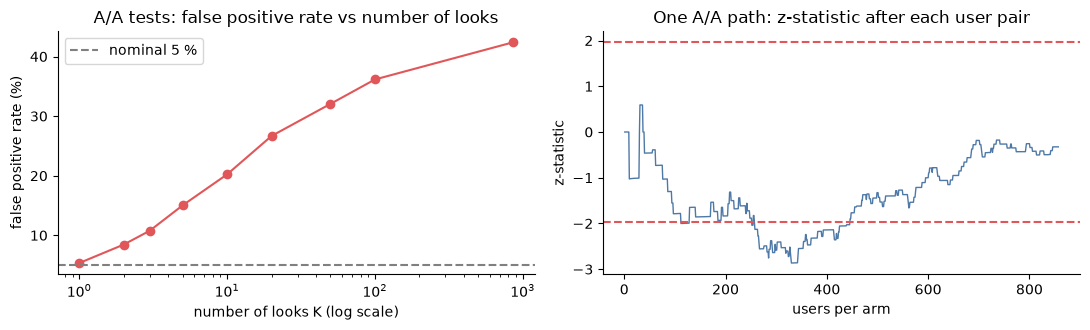

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(fpr_peek.index, 100 * fpr_peek.values, marker="o", color="#E15759")
ax[0].axhline(100 * ALPHA, ls="--", color="grey", label="nominal 5 %")
ax[0].set_xscale("log")
ax[0].set(title="A/A tests: false positive rate vs number of looks", xlabel="number of looks K (log scale)",
          ylabel="false positive rate (%)")
ax[0].legend()
ax[1].plot(np.arange(1, N_FIX + 1), example, color="#4E79A7", lw=1)
for s in (1, -1):
    ax[1].axhline(s * Z_CRIT, ls="--", color="#E15759")
ax[1].set(title="One A/A path: z-statistic after each user pair", xlabel="users per arm", ylabel="z-statistic")
plt.tight_layout(); plt.show()

The real lift is large (4.5 percentage points on a 10.6 % baseline), so 857 users per arm give 80 % power.

With one look ($K = 1$), the FPR is 5.4 %, which is 5 % plus simulation noise. Five looks give 15.0 %, ten looks give
20.2 %, and a look after every user pair (857 looks) gives 42.4 %. The right plot shows why: under $H_0$ the
z-statistic is a random walk. A random walk that you watch long enough crosses any fixed line. This A/A path is below
$-1.96$ between about 250 and 400 users per arm, and then it returns to 0.

*Insight: A fixed-horizon p-value is valid only at the one sample size that you planned. Stop at the first p < 0.05
after 5 looks, and the FPR is 3 times the nominal 5 %. After 857 looks, it is 8.5 times.*

## 3. Group Sequential Design and Alpha Spending

A **group sequential design** fixes a small number of looks $K$ in advance. At look $k$ it compares $|Z_k|$ with a
boundary $c_k$ that is larger than 1.96. The design chooses the boundaries so that the probability to cross *any* of them
under $H_0$ is exactly $\alpha$.

An **alpha spending function** $\alpha(t)$ tells how much of the total $\alpha$ the test may use up to the
**information fraction** $t = n / N_{\max}$ (Lan & DeMets, 1983). It starts at $\alpha(0)=0$ and ends at
$\alpha(1)=\alpha$. Two common choices are (two-sided form, $\Phi$ is the standard normal CDF):

$$
\alpha_{\text{OBF}}(t) = 4 - 4\,\Phi\!\left(\frac{z_{1-\alpha/4}}{\sqrt{t}}\right), \qquad
\alpha_{\text{Pocock}}(t) = \alpha \,\ln\!\big(1 + (e-1)\,t\big).
$$

The **O'Brien-Fleming** (OBF) function spends almost nothing at early looks. The **Pocock** function spends
alpha more evenly. The boundary $c_k$ solves

$$
P_{H_0}\big(|Z_1|<c_1, \dots, |Z_{k-1}|<c_{k-1},\ |Z_k| \ge c_k\big) = \alpha(t_k) - \alpha(t_{k-1}).
$$

The z-statistics have a strong correlation, because $Z_k\sqrt{t_k}$ is a Brownian motion $S(t)$. The code tracks the density of
$S(t_k)$ on the paths that did not stop, on a grid of 1,001 points (trapezoid rule). Then `brentq` finds each $c_k$.
This is the recursive numerical integration of Armitage, McPherson & Rowe (1969). It is an approximation, so the
cell checks it with a grid of 4,001 points. A drift $\eta$ (the expected $Z$ at $t = 1$) gives the power under $H_1$.

In [5]:
def spend_obf(t):
    return 4 - 4 * stats.norm.cdf(stats.norm.ppf(1 - ALPHA / 4) / np.sqrt(t))

def spend_pocock(t):
    return ALPHA * np.log(1 + (np.e - 1) * t)

def group_sequential(t, drift=0.0, bounds=None, spend=None, m=1001):
    # Return (bounds c_k, P(stop at look k)). Give `spend` to compute the bounds, or `bounds` to use them.
    t = np.asarray(t, float)
    c = [] if bounds is None else list(bounds)
    inc = np.diff(np.r_[0, spend(t)]) if spend is not None else None
    s, wg, t_prev, stop = np.array([0.0]), np.array([1.0]), 0.0, []   # start: S(0) = 0 with probability 1
    for k in range(len(t)):
        sd, mu = np.sqrt(t[k] - t_prev), drift * (t[k] - t_prev)      # increment of S: N(mu, sd^2)
        def p_exit(ck):
            b = ck * np.sqrt(t[k])
            return np.sum(wg * (stats.norm.cdf(-b, s + mu, sd) + stats.norm.sf(b, s + mu, sd)))
        if spend is not None:
            c.append(optimize.brentq(lambda x: p_exit(x) - inc[k], 0.5, 12, xtol=1e-8))
        stop.append(p_exit(c[k]))
        b = c[k] * np.sqrt(t[k])                                   # density of S(t_k) inside (-b, b)
        s_new = np.linspace(-b, b, m)
        w = np.full(m, s_new[1] - s_new[0]); w[[0, -1]] /= 2       # trapezoid weights
        wg = w * (wg @ stats.norm.pdf(s_new[None, :], s[:, None] + mu, sd))
        s, t_prev = s_new, t[k]
    return np.array(c), np.array(stop)

K_GS = 5
T_GS = np.arange(1, K_GS + 1) / K_GS
gs = {}
for name, spend in [("O'Brien-Fleming", spend_obf), ("Pocock", spend_pocock)]:
    c, p0 = group_sequential(T_GS, spend=spend)
    c_fine, _ = group_sequential(T_GS, spend=spend, m=4001)
    eta = optimize.brentq(lambda d: group_sequential(T_GS, d, bounds=c)[1].sum() - 0.8, 1, 6)  # drift for 80 % power
    _, p1 = group_sequential(T_GS, eta, bounds=c)
    n_max = int(np.ceil(N_FIX * (eta / (Z_CRIT + stats.norm.ppf(0.8))) ** 2))   # N grows with drift^2
    asn = n_max * (np.sum(T_GS * p1) + (1 - p1.sum()))            # expected users per arm under H1
    gs[name] = dict(bounds=c, n_max=n_max, asn=asn)
    print(f"{name:16s} bounds {np.round(c, 3)} | grid error {np.abs(c_fine - c).max():.1e} | "
          f"alpha {p0.sum():.4f} | N_max {n_max:,} ({n_max / N_FIX:.3f} x N) | E[n | H1] {asn:,.0f}")

O'Brien-Fleming  bounds [4.877 3.357 2.68  2.29  2.031] | grid error 1.2e-06 | alpha 0.0500 | N_max 879 (1.026 x N) | E[n | H1] 707


Pocock           bounds [2.438 2.427 2.41  2.397 2.386] | grid error 1.6e-06 | alpha 0.0500 | N_max 1,040 (1.214 x N) | E[n | H1] 682


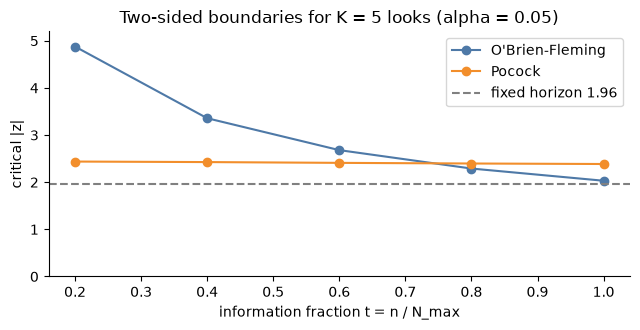

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for (name, g), col in zip(gs.items(), ["#4E79A7", "#F28E2B"]):
    ax.plot(T_GS, g["bounds"], marker="o", color=col, label=name)
ax.axhline(Z_CRIT, ls="--", color="grey", label="fixed horizon 1.96")
ax.set(title=f"Two-sided boundaries for K = {K_GS} looks (alpha = 0.05)", xlabel="information fraction t = n / N_max",
       ylabel="critical |z|", ylim=(0, 5.2))
ax.legend(); plt.tight_layout(); plt.show()

The computed boundaries match the published Lan-DeMets values. For example, the R package `gsDesign` gives
4.877, 3.357, 2.680, 2.290 and 2.031 for O'Brien-Fleming. The 4,001-point grid changes them by less than $2 \cdot 10^{-6}$.
Both designs spend exactly $\alpha = 0.0500$.

The early looks cost power, so the design needs more users at the last look to keep 80 % power:

- O'Brien-Fleming: $N_{\max} = 879$ users per arm, only 2.6 % more than the fixed $N = 857$. Its last boundary is
  2.031, close to 1.96. Under the real lift, the expected sample size is 707 users per arm.
- Pocock: $N_{\max} = 1{,}040$ users per arm (21.4 % more). It stops earlier on average (682 users per arm), but
  if the effect is small, it runs much longer than the fixed test.

O'Brien-Fleming is the usual default: a stop at the first look needs $|z| > 4.877$, and the final analysis is almost
the fixed-horizon test.

## 4. Always-Valid Inference: the Mixture SPRT

A group sequential design still needs a plan of looks. The **mSPRT** (Robbins, 1970; Johari, Pekelis & Walsh, 2017)
allows a look after *every* user. It compares the likelihood of the data under $H_1$ with $H_0$, but $H_1$ is not one
effect size. It is a **mixture**: the effect $\theta$ has a normal distribution $N(\theta_0, \tau^2)$ around the null
value $\theta_0$.

Let $\hat\Delta_n = \bar Y_{B,n} - \bar Y_{A,n}$ be the difference in means after $n$ users in each arm.
Let $V_n = \operatorname{Var}(\hat\Delta_n)$ be its variance. For a conversion metric with the pooled rate $\bar p$,
$V_n = 2\bar p(1-\bar p)/n$. With a normal likelihood, the mixture likelihood ratio has a closed form:

$$
\Lambda_n = \sqrt{\frac{V_n}{V_n + \tau^2}}\;
\exp\!\left(\frac{\tau^2\,(\hat\Delta_n - \theta_0)^2}{2\,V_n\,(V_n + \tau^2)}\right).
$$

Under $H_0$, $\Lambda_n$ is a nonnegative martingale with $\Lambda_0 = 1$. **Ville's inequality** then gives
$P_{H_0}(\exists\, n: \Lambda_n \ge 1/\alpha) \le \alpha$. So the rule "stop when $\Lambda_n \ge 1/\alpha$" keeps the FPR
at or below $\alpha$, whenever and however often you look. The **always-valid p-value** and the **confidence sequence**
(the set of $\theta_0$ that the test does not reject) are

$$
p_n = \min\!\Big(p_{n-1},\ \frac{1}{\Lambda_n}\Big),\ p_0 = 1, \qquad
\mathrm{CS}_n = \hat\Delta_n \pm \sqrt{\frac{V_n (V_n + \tau^2)}{\tau^2}\left(2\ln\frac{1}{\alpha} + \ln\frac{V_n + \tau^2}{V_n}\right)}.
$$

The mixing scale $\tau$ is a tuning choice. This lesson sets $\tau$ to the effect size of the design ($\Delta$).

In [7]:
def log_lambda(diff, v, tau, theta0=0.0):
    # log of the mSPRT mixture likelihood ratio for a normal mean difference.
    v = np.maximum(v, 1e-12)
    return 0.5 * np.log(v / (v + tau ** 2)) + tau ** 2 * (diff - theta0) ** 2 / (2 * v * (v + tau ** 2))

def cs_halfwidth(v, tau):
    # Half-width of the (1 - ALPHA) confidence sequence.
    return np.sqrt(v * (v + tau ** 2) / tau ** 2 * (2 * np.log(1 / ALPHA) + np.log((v + tau ** 2) / v)))

def msprt_stop(sa, sb, tau):
    # First n (users per arm) where Lambda_n >= 1/ALPHA; N_MAX + 1 if it never crosses.
    pbar = (sa + sb) / (2 * n)
    ll = log_lambda((sb - sa) / n, 2 * pbar * (1 - pbar) / n, tau)
    crossed = ll >= np.log(1 / ALPHA)
    return np.where(crossed.any(1), crossed.argmax(1) + 1, N_MAX + 1)

def gs_stop(z, g):
    # First look n where |z| crosses the group sequential bound; N_MAX + 1 if it never crosses.
    looks = np.round(g["n_max"] * T_GS).astype(int) - 1
    crossed = np.abs(z[:, looks]) >= g["bounds"]
    return np.where(crossed.any(1), looks[crossed.argmax(1)] + 1, N_MAX + 1)

TAUS = {"mSPRT tau=0.01": 0.01, "mSPRT tau=Delta": DELTA, "mSPRT tau=0.15": 0.15}
def run_scenario(p_b, seed):
    out = {k: [] for k in ["fixed", "naive every n", *gs, *TAUS]}
    for sa, sb in paths(P0, p_b, seed):
        z = z_stat(sa, sb)
        out["fixed"].append(np.where(np.abs(z[:, N_FIX - 1]) > Z_CRIT, N_FIX, N_MAX + 1))
        hit = np.abs(z[:, :N_FIX]) > Z_CRIT                       # look after every user pair, up to N
        out["naive every n"].append(np.where(hit.any(1), hit.argmax(1) + 1, N_MAX + 1))
        for name, g in gs.items():
            out[name].append(gs_stop(z, g))
        for name, tau in TAUS.items():
            out[name].append(msprt_stop(sa, sb, tau))
    return pd.DataFrame({k: np.concatenate(v) for k, v in out.items()})

stop_aa = run_scenario(P0, seed=2)                 # A/A: H0 is true
stop_ab = run_scenario(P1, seed=3)                 # A/B: the real Hillstrom lift is true
fpr = (stop_aa <= N_MAX).mean()
print("false positive rate (A/A, any look up to the test's own end):")
print((100 * fpr).round(2).astype(str).add(" %").to_string())

false positive rate (A/A, any look up to the test's own end):
fixed               5.03 %
naive every n      42.22 %
O'Brien-Fleming     5.18 %
Pocock              5.05 %
mSPRT tau=0.01      0.15 %
mSPRT tau=Delta      2.7 %
mSPRT tau=0.15       2.7 %


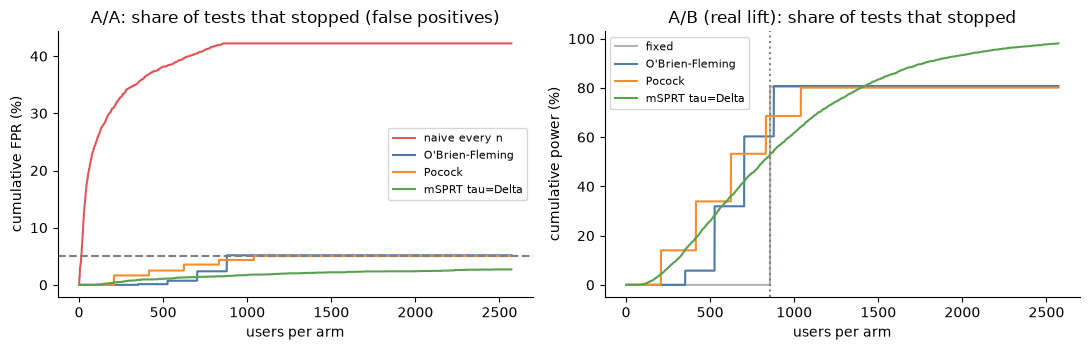

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
grid = np.arange(1, N_MAX + 1)
style = {"naive every n": "#E15759", "O'Brien-Fleming": "#4E79A7", "Pocock": "#F28E2B", "mSPRT tau=Delta": "#59A14F"}
for name, col in style.items():
    s = np.sort(stop_aa[name].to_numpy())
    ax[0].plot(grid, 100 * np.searchsorted(s, grid, side="right") / SIMS, color=col, label=name)
ax[0].axhline(100 * ALPHA, ls="--", color="grey")
ax[0].set(title="A/A: share of tests that stopped (false positives)", xlabel="users per arm",
          ylabel="cumulative FPR (%)")
ax[0].legend(fontsize=8)
for name, col in {"fixed": "#BAB0AC", **style}.items():
    if name == "naive every n":
        continue
    s = np.sort(stop_ab[name].to_numpy())
    ax[1].plot(grid, 100 * np.searchsorted(s, grid, side="right") / SIMS, color=col, label=name)
ax[1].axvline(N_FIX, ls=":", color="grey")
ax[1].set(title="A/B (real lift): share of tests that stopped", xlabel="users per arm", ylabel="cumulative power (%)")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The left plot and the printed rates show the FPR when each test runs as designed:

- The naive analyst who checks the z-test after every user pair reaches 42.22 %.
- The group sequential tests stay at the nominal level: 5.18 % (O'Brien-Fleming) and 5.05 % (Pocock). With 4,000
  paths, the simulation standard error is about 0.35 percentage points.
- The mSPRT with $\tau = \Delta$ looks after *every* user pair up to 2,571 users per arm and stays at 2.7 %.

The mSPRT is conservative: Ville's inequality is an upper bound, and the real FPR is lower than $\alpha$.
With $\tau = 0.01$, the FPR is only 0.15 %, but the next section shows the cost of this choice.

## 5. Power and Stopping Time Under a Real Effect

The cell summarises the A/B scenario. **Power at N** is the share of tests that rejected $H_0$ by $N$ users per arm.
The **average sample size** counts the users of each test until it stops. A test that never stops counts with its
maximum: $N$ for the fixed test, $N_{\max}$ for the group sequential tests, $3N$ for the mSPRT.

In [9]:
cap = {"fixed": N_FIX, "naive every n": N_FIX, **{k: g["n_max"] for k, g in gs.items()}, **{k: N_MAX for k in TAUS}}
rows = []
for name in stop_ab.columns:
    s = stop_ab[name].to_numpy()
    rows.append({"test": name, "FPR %": 100 * fpr[name], "power at N %": 100 * (s <= N_FIX).mean(),
                 "power at max %": 100 * (s <= cap[name]).mean(), "max n": cap[name],
                 "avg n (H1)": np.minimum(s, cap[name]).mean(), "median stop n": np.median(np.minimum(s, cap[name]))})
summary = pd.DataFrame(rows).set_index("test")
print(summary.round(1).to_string())

                 FPR %  power at N %  power at max %  max n  avg n (H1)  median stop n
test                                                                                  
fixed              5.0          80.5            80.5    857       857.0          857.0
naive every n     42.2          91.8            91.8    857       274.4          173.0
O'Brien-Fleming    5.2          60.3            80.8    879       706.6          703.0
Pocock             5.1          68.6            80.1   1040       686.9          624.0
mSPRT tau=0.01     0.2           3.1            92.8   2571      1646.5         1600.5
mSPRT tau=Delta    2.7          53.2            98.1   2571       937.7          815.0
mSPRT tau=0.15     2.7          47.1            95.9   2571      1028.6          911.5


The table shows the trade-off between flexibility and sample size:

- The fixed test has 80.5 % power at $N = 857$, but it gives no result before $N$.
- The group sequential tests reach the same power (80.8 % and 80.1 %) with fewer users on average.
  They need 706.6 and 686.9 users per arm instead of 857.
- The mSPRT with $\tau = \Delta$ has only 53.2 % power at $N$. It pays for the freedom to look at any time.
  But it does not have to stop at $N$: it reaches 98.1 % power by 2,571 users, with a median stop at 815 users.
- The mixing scale $\tau$ matters. With $\tau = 0.01$ (too small for this effect), the average stop moves to
  1,646.5 users per arm. With $\tau = 0.15$ (too large), it moves to 1,028.6.
- The naive peeker has the highest "power" (91.8 %), but 42.2 % of its A/A tests are also "significant".

If you can plan a few looks, a group sequential design is the most efficient. If you need to look at any time,
for example to stop a harmful change fast, the mSPRT is the safe choice. Set $\tau$ near the effect size that you
expect, for example the median lift of your past experiments.

## 6. Replay: the Real Hillstrom Experiment as a Stream

The real experiment sent all e-mails on one day, so the data has no arrival time. The cell shuffles the users of
`Womens E-Mail` and `No E-Mail` into a random order (a fixed seed) and treats this order as the arrival stream.
After each user it updates both arms and computes the always-valid p-value, the confidence sequence and, for
comparison, the naive fixed-horizon p-value. The arms now have unequal sizes, so the cell uses
$V_n = \hat p_A(1-\hat p_A)/n_A + \hat p_B(1-\hat p_B)/n_B$ for the p-value and the confidence sequence. The same $V_n$
in both makes them agree: the sequence excludes 0 when $p_n < \alpha$. The monitoring starts after a burn-in of
30 users per arm, so that $V_n$ is never 0.

In [10]:
stream = (df[df["segment"].isin(["Womens E-Mail", "No E-Mail"])]
          .sample(frac=1.0, random_state=7).reset_index(drop=True))
is_b = (stream["segment"] == "Womens E-Mail").to_numpy()
y = stream["visit"].to_numpy().astype(float)
BURN_IN = 30                                       # users per arm before the first look
n_b, n_a = np.cumsum(is_b), np.cumsum(~is_b)
s_b, s_a = np.cumsum(y * is_b), np.cumsum(y * ~is_b)
ok = (n_a >= BURN_IN) & (n_b >= BURN_IN)              # start to monitor after a short burn-in
pa, pb = s_a / np.maximum(n_a, 1), s_b / np.maximum(n_b, 1)
diff = pb - pa
v = np.where(ok, pa * (1 - pa) / np.maximum(n_a, 1) + pb * (1 - pb) / np.maximum(n_b, 1), 1.0)
tau = DELTA
p_av = np.minimum.accumulate(np.where(ok, np.minimum(1, np.exp(-log_lambda(diff, v, tau))), 1.0))
half = np.where(ok, cs_halfwidth(v, tau), np.inf)
p_naive = np.where(ok, 2 * stats.norm.sf(np.abs(diff) / np.sqrt(v)), 1.0)

users = np.arange(1, len(y) + 1)
stop = int(np.argmax(p_av < ALPHA))
last = len(y) - 1
se_full = np.sqrt(v[last])
print(f"stream: {len(y):,} users | mSPRT may stop after user {users[stop]:,} "
      f"({n_a[stop]:,} control, {n_b[stop]:,} treatment) = {100 * users[stop] / len(y):.1f} % of the data")
print(f"at the stop: lift {diff[stop]:.4f}, always-valid p {p_av[stop]:.4f}, "
      f"95 % CS [{diff[stop] - half[stop]:.4f}, {diff[stop] + half[stop]:.4f}]")
print(f"all data:    lift {diff[last]:.4f}, always-valid p {p_av[last]:.1e}, "
      f"95 % CS [{diff[last] - half[last]:.4f}, {diff[last] + half[last]:.4f}], "
      f"fixed 95 % CI [{diff[last] - Z_CRIT * se_full:.4f}, {diff[last] + Z_CRIT * se_full:.4f}]")
print(f"first user with naive p < 0.05: {users[np.argmax(p_naive < ALPHA)]:,}")

stream: 42,693 users | mSPRT may stop after user 1,782 (919 control, 863 treatment) = 4.2 % of the data
at the stop: lift 0.0468, always-valid p 0.0497, 95 % CS [0.0000, 0.0936]
all data:    lift 0.0452, always-valid p 6.9e-42, 95 % CS [0.0343, 0.0561], fixed 95 % CI [0.0389, 0.0516]
first user with naive p < 0.05: 373


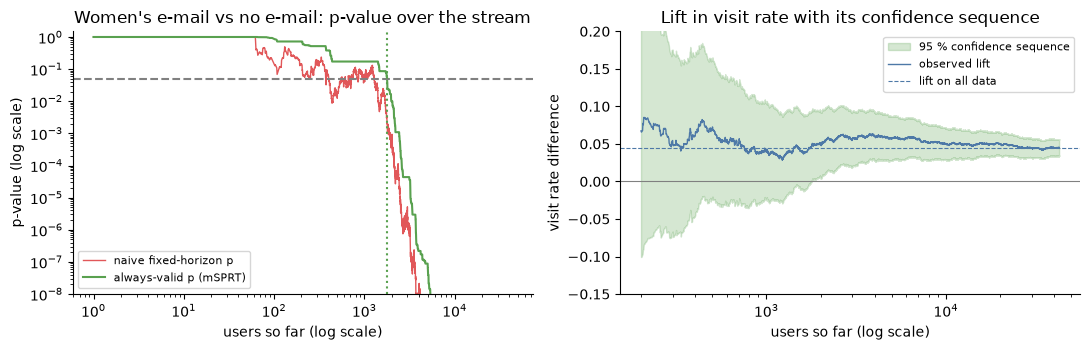

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(users, p_naive, color="#E15759", lw=1, label="naive fixed-horizon p")
ax[0].plot(users, p_av, color="#59A14F", lw=1.5, label="always-valid p (mSPRT)")
ax[0].axhline(ALPHA, ls="--", color="grey")
ax[0].axvline(users[stop], ls=":", color="#59A14F")
ax[0].set_yscale("log"); ax[0].set_xscale("log"); ax[0].set_ylim(1e-8, 1.5)
ax[0].set(title="Women's e-mail vs no e-mail: p-value over the stream", xlabel="users so far (log scale)",
          ylabel="p-value (log scale)")
ax[0].legend(fontsize=8)
m = users >= 200
ax[1].fill_between(users[m], (diff - half)[m], (diff + half)[m], color="#59A14F", alpha=0.25, label="95 % confidence sequence")
ax[1].plot(users[m], diff[m], color="#4E79A7", lw=1, label="observed lift")
ax[1].axhline(0, color="grey", lw=0.8)
ax[1].axhline(diff[last], ls="--", color="#4E79A7", lw=0.8, label="lift on all data")
ax[1].set_xscale("log"); ax[1].set_ylim(-0.15, 0.2)
ax[1].set(title="Lift in visit rate with its confidence sequence", xlabel="users so far (log scale)",
          ylabel="visit rate difference")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The always-valid p-value falls below 0.05 after user 1,782 (919 control, 863 treatment). That is only
4.2 % of the 42,693 users. At this moment the lift estimate is 0.0468 and the 95 % confidence sequence is
[0.0000, 0.0936]: wide, but it excludes negative effects. With all data, the lift is 0.0452. The confidence
sequence [0.0343, 0.0561] contains this value at every step and is wider than the fixed-horizon interval
[0.0389, 0.0516]. This extra width is the price of a guarantee that holds at every step.

The naive p-value is below 0.05 for the first time at user 373. The left plot shows that it then goes back above 0.05
several times. A team that stopped at user 373 had the right sign here only because the effect is real and large.
In an A/A test, the same rule gives the 42 % FPR of section 4.

*Insight: The mSPRT turns "may I look now?" into "look whenever you want". The always-valid p-value only goes
down, and the confidence sequence is correct at every moment, so a stop at any time is a valid decision.*

## 7. Which Test to Use

The numbers come from the summary table in section 5 (A/B scenario with the real lift, $N = 857$).

| test | when you may look | FPR (sim.) | power at $N$ | avg. users per arm under $H_1$ | use it when |
| :--- | :--- | :--- | :--- | :--- | :--- |
| fixed horizon | once, at $N$ | 5.0 % | 80.5 % | 857 | the sample size is fixed anyway (one e-mail send, a weekly cycle) |
| group sequential, O'Brien-Fleming | at 5 planned looks | 5.2 % | 60.3 % | 707 | you can plan the looks; you want early stops for large effects with almost no loss at the end |
| group sequential, Pocock | at 5 planned looks | 5.1 % | 68.6 % | 687 | early stops matter more than the maximum sample size |
| mSPRT ($\tau = \Delta$) | at any time, as often as you want | 2.7 % | 53.2 % | 938 | dashboards that people check all the time; fast stop of harmful changes |
| naive peeking | at any time | 42.2 % | 91.8 % | 274 | never |

Tool support: tea-tasting 2.0 (Lesson 03) has fixed-horizon tests only. Commercial platforms offer sequential
options: Optimizely's Stats Engine uses always-valid p-values based on the mSPRT, and Statsig and Eppo have
sequential testing modes. Read the documentation of your platform to find which method and which $\tau$ it uses.

## Real-World Use Case

Optimizely is a commercial A/B testing platform. Its customers watched results in real time and stopped tests when
the dashboard showed significance, the peeking pattern of section 2. In 2015, Optimizely replaced its fixed-horizon
statistics with the **Stats Engine**, which reports always-valid p-values and confidence intervals. Johari, Pekelis,
Walsh and others describe the method in a KDD 2017 paper. Its title is "Peeking at A/B Tests: Why it matters, and
what to do about it". The core of the method is the mSPRT of section 4, with a mixing distribution fitted to past experiments.

Clinical trials use the other approach. Many trials have an independent data monitoring committee that looks at the
data at a few planned interim analyses, with O'Brien-Fleming type boundaries. A trial can stop early for a large
benefit or for harm, and the final analysis keeps almost the full power of a fixed design. Online teams copy both
ideas: Spotify's experimentation team, for example, published a comparison of sequential testing frameworks in 2023.